# SVRで曲線を回帰する：馬力から燃費を予測しよう

**Google Colab用・CPUで実行できます。** 上から順に「ランタイム → すべてのセルを実行」を選んでください。追加ファイルのアップロードやAPIキーは不要です。

この実習では、公開された実測データを使い、RBFカーネルを使うサポートベクター回帰（SVR）を試します。

- 直線と曲線の回帰を比べる。
- 予測曲線の上下にある **εの帯** とサポートベクターを見る。
- **C、γ、ε** を一つずつ変更して違いを観察する。
- 訓練・検証・テストの役割を分けて評価する。

説明は日本語、図のラベルは英語です。図は実行時に `svr_outputs` フォルダへPNGとして保存されます。

## データと予測するもの

[UCI Auto MPG](https://archive.ics.uci.edu/dataset/9/auto%2Bmpg) は、自動車の市街地走行時の燃費などを収録した公開データです。

ここでは、入力を **horsepower（馬力）一つ**、予測対象を **mpg（1米ガロン当たりの走行マイル数）** とします。mpgは大きいほど燃費がよい値です。説明変数を一つにすることで、予測関数を二次元の図に曲線として描けます。

同じ馬力でも燃費にはばらつきがあります。重量や年式などを使わないため、これは燃費予測システムの完成版ではなく、SVRの仕組みを見るための実習です。馬力の変更が燃費に与える因果効果を推定するものでもありません。

**出典**：Quinlan, R. (1993). Auto MPG [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5859H  
**ライセンス**：[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)。元のデータと欠測を除いたデータを区別して扱います。

In [1]:
import sys, io, zipfile, urllib.request, base64, zlib, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

SEED = 42
OUT = Path('svr_outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, TEAL, NAVY = '#2684d9', '#ef8625', '#169b98', '#102a4c'
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__, '| matplotlib:', matplotlib.__version__)

Python: 3.14.0
scikit-learn: 1.9.0
pandas: 3.0.3 | matplotlib: 3.11.0


## 1. 公開データを読み込む

まずUCIの配布ファイルを取得します。取得できない場合は、このノートブックに内包した同じデータのスナップショットを使います。学習用の人工データへの置き換えは行いません。

元データは398件です。馬力の欠測を除外すると392件になります。欠測の除外件数とデータのハッシュを表示し、どのデータで実行したかを確認できます。

In [2]:
DATA_URL = 'https://archive.ics.uci.edu/static/public/9/auto+mpg.zip'
SNAPSHOT_SHA256 = '48b830e11feee5572525f8f1691ddb9d38d3d7b7063edcd8fca672c2a5e17d8d'
# UCI Auto MPG, CC BY 4.0. Original auto-mpg.data, losslessly compressed.
SNAPSHOT_B64 = 'eJydXdty27qSfY6/gqWX2aem4iEuvD3N/AokMTZ3KFGHpJw4Xz8FAkQvgE3J+zzFZVsdXBqrV69uwKJ+zbMsq7MsU3m1fJ1lmVD5+qUqcv3qvyuXb1Z5lolvh9N7+zEOfTtn9qu279vsYvrueD+8iIKMFsGSKN237XfLRq1GxWtBRo/37vQzm35+9mb8mSmZH14EjNB/bT9GdpVWJRmDEd76z8twn9+zycxt33dze3gRJcxX89YUO19zOWVje2z7bJrmw4uowJD7RfsRDYZ0sxrKcY4/hvGczcPYXYdoqbRsgpkmTFQrLchMnph5M7353bVZkduV0mSrCHOTMgxJq2Ldy6zh97K73ExvYls0J+mHu9gScrVV4/TCqv+4j59Z13XJwIIFKcmYlgU7ydtwnTtzyk5mNn13NbFvNeRb9KWqi5wdmN1AczmaaTLnYczOtz62VqtgrQL3LxU7svNwfmuz07vp+/b61o7Z1EYTVbRqoiRzZb46Rea2OF21/zrdz8Z+OvaNPOd8tSpX38ganCrt52W4zm12MmM/fGEfVF6X7GzduWyn2cxt9su8Ddfsr+nXvw4v0pnUy+ELC9gUr/lqXVWrn/j5WJPq22EePofZZKdhHK4mu9jzbn1FurNUxqcADdZ0QAvW8c73aW7HgBzOVDhbTUWmqkqzpqyrvA/jtZ0PL1IEK5J2oYYBFXW1Wik3J/RiPtqxO/08vMgqLBWMoa7JkIVdb0iH4ahvh7OZp/s1u/WFyA8vsuTs6DJ8KWq1niZJyCO/HT6G/uf0y7y1V7tZIju3/f13m03t2VwPL94N3FbSRGG5StrKCu3e2vtbO8xZkevYIyii2PO5mtHcNOW3g7mfu0zkedZP8WgIqGPHKtjRTMYcs6Zpo5USfhtjP5VSQXADG8fLL7vbMtp+dCKYTqnrrYN7J3ob20vfXQ8vfkEXZChZPC1FmI7eeNEPWeSxEVpa8EqtqpIdiwWEz+y0xFPBxVNJO65VHbZZ4alwkHeWNtb4lUjjaBOWVlcqWIlg+L3LhMzz8392IAR3IGraZkJd3CJZpudcJDj50b6ZTCo7tegcsJAmZZ1sldhCWmTIIpn/9P+6f9zO6bBdPh4L2vNbd50taDeEP4qIBm26LMmJFVqJHbAkMwT4Iifs16phF2lLo7LTfZqHSyBBi1EgejQ2pSRv9BF7bDij4BbKEi7OKDArz4jqJ2unZF2zpuzaXcxsmUIc1lk+q2UI6ytpFF8gVhDUK+BC5Kwi2oeEC2XHcbi/vZtLMkACuoJOowjMbz3T4jmL5Pm2zpuS9TeO+UmWX9VkrCkKdrYObC7D1ZwGzzX8/7ZZOjJW0XmKtmGZ5Wm4X+fxM5v+fe/G9onNsB2FhRTO5rodk/lhxm41Bw5X0OIRuMqmTMFVJJQjm27DOJvjcJ9XkiU5gKskhNS8ZoEkATg/SPaAxaci5WzxnH90Y3vsxnMyYfawCoIVwvDAju7TbK5vhxepIFSHk1oTqZE2jwl2YEyXdjxZfzuZ29jZYJhEBA98SUQQUm2tyW+H4db2NpvIDy8+B7ZGqiZ80npbCLxEHz39FhEfUpYPgRlYlgpmlpcQ+cHMj87MmZD6eHhRgsYiwictAAWPrdTWA+KY1PdmCb2HF0WRCbyopFmKUgRzPk+JIq8zwwdwS2+IicIKwTIDE70MZ7vkQsTMVnArLggtVmabQM/Jcu2Ftj9NTGSVQr9kEpN3M57n4RZH8+q1WD008qmAPm5hrEFKFYd+BmuKWzqbtYfhBcSWHihkunTz563N1OHFZ/gPCFCED6uxDT4EtvvwGIZJlmiJKEs23q8LekXouhc46Qh5dJX/ceBUdcHaeiwi8DFOhBRqhWn5BXVjL/gSCfIBU+4F3+qZPAU5mI+XklM3nEYlOHFJ5iQulZRLe+lMRqB6MeO/7920u5OkIuiCSFm0Yk466NvJHEdgjpL3DNoBXZSsvaE/T5fh2PWtzV9nk9V1Ng6fpm93ozmJQ1pLmSR8q7+Nn1Pfjtm1/WXDrzMZYqWKcQg1BEU5Co1TfTtczJ+zycbf0hKPWxs7Hb+3dcMPDsjolrbwsq3OmzRHkXvE+zRcT8N9nDjbnLKpZaMTwQP9eTTXlYR7g88ZZVWxg91NPWK6tUnww6hlQw6uExT9GDKhi5bhWGQKw3QhRBISN4CshVjNIZCyYkpTNVtIjsWU1RaExZKL1lLUDTu0sb2ae29JBDdLFt9VU+zvrcN3b4rWHo5DA6QUciuKh8QhCpGvppD8UfyCxSrycruNPlbfNyoiM0JiXlHERl2Aj9je1HOpIs+3cZHhX2W+znoHUiGggU0fNxRA6qm9zhaj1SIN6X8eOBST6fJj0qQSNLSp0ZhAcl7zeM3iiApwpXMtk11VLI58IWCriiBEoq11K8fBplZM+NkpuzQFv1xJZMQknA8+AHOQ2Ut+7ZYk5tRmp95MU3dKNgTIBdSHqEARbciyiP18/gr+SgX4C5ON2c6yI14sxsny9aGKGJSIJ0uRNvscxp/tiIson5WKmkKwdn2Jom9P82jsJ2izYQ1L7qCpWvI2E1IFw6yfqWk2iMR4kCzph+k7c51jZW4nHadMpeb95jp8GJrvM9VLNjoFebWpezzP7POdKaZ1D/WsotNQiTkazqai87z00YTin4/A1lQcpKf7zbpc284LZRTPTm3TpORE7aUokrVVEuI1FMcilEKBat9haUwlynncinmaNN2P9/G4S7dBh9NNw44M6PZHN9lINt67KSmv7bhZRbSkSN0sCNOQvO6EVolMaTUDodWMS1KHlGtPJRMJ5VJ8FgwsiZKlBpJzRUMi1ydqU9qyhF+fNHWIBINUlHVWLub3kjqokH+khA3LYCJP6ixqU0PAIhahKpTnpCZ2EDl5rK59lPEZpE2Kqy1FIqyoSM9yAieXFrGUQ+dYj+IpB1W5sylq8oBzKCE7IkRtnJSznh8vFdhQd85uY/f78OL5gZ1wSRPWIJbVZbX1K5pwnahRQZC0EYgiZ6pGKRIkL+Y6m1jn8dsUS2WyqJlthNKqraxGLsUmTXXJj2VNmnT7FQ1FKYKUKKr6OqKxPuBDFq4PjgmKXGUq/yqs9loo98vjvDwsMhwbWecVe+A8koQmBKyRsnCpSizS5CxcDhcHJvmT8KcEKSceTPRO+GNbEbCgWGNNPCdTSUh+XlNsCCpLNBQxhOJp9Y86s6LhxMQllrfpXNm4uY3rawzQCLhHmXRGIFiiDkrkMVpqBEu/IA+09jpMayUZel9rx3IyhCXsH6E0aGeVXFh6ThSrWjyxlFRbIdEon1SuVIkF/cQlKIF8SoyhssB7O2k9U3scO1sdirr2WElKUJechwe9l0ruKJlArgi3fDakmbS7v/++B8nsaYalixR59G56yhjlJ12qmj2kX9DhWI1ASxqlB/7NFq+CSMNqKwpYgEgpkqZQ9GP4HR3XvVNPuS2NJ2bzZzO976cGFdBIRWoKbWsSYRGIKKsoiEOKUjPT2vZ+AIjAopQQqvNcPUK0KulsAYIV0QZqnIx8lRSsKLjuWaHyULTOQGDKZwRGUu2dTiCyvvmUxHlW6dObnMEty/twPZvs1H1YsMLRAEEH71ON2M5IfTtM96MZ71+IOLaQvD1c63x+i9cmDqMEdhjaofHIGylYFYDN3RHjoU2naFiTaUzlozOkQ0oHQF/DWBFLXMPVjKf3r5gC9uoZcMHyDpaYR4ktUU8vuxVfqOHxeYMVpmKPTFfKdnObbowDzA6AYz2lYHbSpQxWKNstCWoovG3iQZGqdtBb5b01CchNYLPx/kVxap82gPxFCodPIXGh2n6/xf8BXaioLubxrfgqXcATVFFRNzITSZMxNeZXK8f2ts1qTT8/380vq1ZRj6UsJWdIkuwVbV2Ujv4xmfxvuVtMI81ZiTJtHSs2/TGuM7phIxzCeJWS9oLhpXG9hegEBu+SFqvaDGoVFfKnSYTg0S/Wf9jBYOAuqCxac5hgpnkc4tiiKDuG2la1KVEXz/o2IV5C7JbUPeRJQLHLSzDzZ5vQCxJjaa0TIoCt7HYgWytNrVl8inasYSeG/TVYCMjZiY3meOzmvRwS7CpJBdMq3f6bOS2rA5tPtQPUhkuqNdOxTRQNvn6IEmJDcEtD2XSusyVgoLeom9MiB2FEan3u44QPtQyqZpR0TskPYy1DQX8QOZ7tKQlBs0nb34uUKGWnj5NlS1AlJ8kPi75QmPJsqQTupkTSFB34Xx2dCeBLDdmAjjo+FcaScYEy5GrEYusiPy4oyMqPwOGkpI7S6rUiGxElpnquyMMeRekL9hgrmg6V1GfbHuKW3sF7wfZKUFu/Fy/Lf5iSP+pSatICcclklVC2crubZoB0ZlTUngobkPZDF1xRUnKzlq81mdmm43DfJxIMIN7ifR+Xme1U0tAWz3RUkbaDlCx59qidXvohd1d5uP4mqtcymSEUv1wx5QFK5kRwIkPRHSQCbpD+IS2VOV35ka9y181mewdSuqknR6hk+yKkfBWctV/DcP78xxFlHZiFzF8hkvxDrFtdYJMU5s88qST1j0EGM91sdbDdS8KAkqgitC2u1Dvxb3M22dt7Z/MUx1lSp0RhDauxsHcrv/lYmLzJpr8D4CS8O1KT6WpthUcvRN3s/D82Srk8LWWTtP6iJmmBXIrnAqh2FLwbEFL5AFxG+u13J+CyPUVxmQTWCjxhQ3EdL3tQDCyoSqU2BzimuI5SAqCEg6wsGvvvFsGlgBEUcQrAF0oaSlRV5AAB4YbejG12G9tL147ZR51UcdjyvKygFA4BOeI8wOKwZkKiimwojyNuwNVM3IovlmydbHUdaG9EhgBrZfWG9txO34/t9Y8t0rgSXvG4YK1quJeBGGXOXd/bixntR9cnXaF7FUbyKp+DEd59ZqeFgfOJHFyUr8N6r0wVHOqHyOuvuEJFI/EEHCHqLJbufcHiN/DUnBDFZ0wV4KU5nZZ2g4UcwvUE4UtZaZMcDmkBlAoS54XeddP9z91fJz28KFbXtWjFQEvtzl4Vkasie7PsSjqHS+o5mNGBpuuds4pPjhnH4Vf2Ni1RpniCUYjD60QJo358F3n2bubT+9EsYtYO9wNdBV0URveo34sawCW0fsDtzJwKoV4QqdLK4+k+W3u202VsL67GXjB+BycAbjkpdzar7TWsiEg+Pg1aUsj2TL6KGwqG+5uJWqqqZ3GyQPzQ7HL6TuYFuYl3CVZHJR/0+Uq1fYJiT+ONWAUBpGcVFYveIPEyE4WTrAoaWrTFyC52xVSASEjJhIPIaqfLIev/jr0EG1Ih36CYKfgdwE6M3lzP5h7Z3enKVxuqUcW9ghawhmM86UhZDcqKVtR36Ck+LN78fr+e29HdXdsR1ACnIDCTLY4CYSNDgCwaH0oRFdn0oli8KdP9aoe3tsfs1LWw8EKbUofF21aj++7H7IALYRXkP0ihIQoVCPmJJukkTpWz4Qhy6Rx5N0yZS04ApncKizn1OBR4cKFp+/I/lyiy4e00LC9S6kWAEopEmRVzcHJ8WRFycB0O2Y4WCG9b2KbFrYpX4yMAxSYE1QtJpvC/1ytDUdFn31V41UDJvAs2VBzq0UZF2KFwJOu1lu/68KLVMuEk+7NVju0K+/+xqh8eoOzctVNr170k0+BU+MgFlnOXzauBbnX2rZIlMVlgJ94zrOeCDzTBTJjnW38iWuN+vk8gZE4M0NOaOm1Syd5+x5MT/L1JLD7CqLbinmiWM7BPGJTatOPVu4TB9MMVY7Kb8oY3YJUHsihJxj1f7W79cDFWwciXn24IA9VBiip12pqrRq5ZdbPYexDfCxqZ+11vb8XZ2/vQXn3kQ7ZAESrKqosUZOudaw9+pg/ei2lwQ+rUc0032iCa/WXu82A7LYrgLIjWGFHoqHqBjLV3Mdd/xVPl+Qw8z1JFCxfzmeAdDysAvCmrRSxcbQnD+XJWHmwlpHrRgsUNOdOtPXX2zp7Ml1/a3wEFB9VnorGv/Wlv75+uPFkyi4XaDa19jZZAUlrMCKZYCqmxpoVy271dKCfbeF9+kHQAr41O5BOO5qhrugnwZJum7Eihl7lNGNs302Njb/bXfB+P1oH97B8cfZkDrZSpA9+t+BWnWywW6bxOcxjci4t5u94v2YLkwAz4BDqSmQAzWTnVDSytO2KDH/aurvNj6o7ujDwoFUYtTOsMoxt1y+SaUNoI2xcRxs2rOrhOw+XqCIJ4MimkKvV2Um3fnUz2NiPxdA6pU7GJKmMVpuCwhdAceLsNS7VXhciORBvfCcM6UMnGvWk2o33LIptsO5oreDxYfp2nOW20/DLPvy+G8qVgZFdWIKDRs1M1amqrobWoWSxPWED7h7BcesUMuGGEKfs6P5IeS/1msVAsP3pQjARt3SuYNRYj3xYFzenS6WC8cL8BsNUbQGwscz1ZWkfcFfINVJ1BKKY1Ti7wnLpxOJ1cQfuJEgb3+EukZJES1ttNcyPbNJDQekvyTR9mm4hQ9O3FXKfljoRonkQgCdP0fKJhIlBm71vIxZsexP8atXVFtuL4r2NqshOwN7lks41D/TKs/FlotFeX4qVvNtWWMnnyoGCFVXL0aOEfy2jl47abCsMkGF0bsCgyohJNjqFCCFLwhJHi9tLJLPSUglvZNJD5N1mWCSM8yHTlpvnVhtvFlFOuHrzKAJvgj1Pz+EHHSAQCgYVquzndPdMbd+MfWSLSIukyHGJZScjqtfN0i+PiON3/D4OF5GevtBIZ9spS3x7NONh69K9r9n9h/M6+coWTR3CF/berfSxvBmVIOXVgsVWy1woaFDbWbQ/XwaJU1CH1/s120WB0BveO3qLxUjaJV664mgQLrAWUmxoH4cN068ZuXlQT6c7pEgHp2a+KQqkqgovL3BHeJqoFZUstSLl3Avn6DbhPQ7zI14ebuBbU9udhNOchJlma3nmAyj4JOtITm4bpFVJc2o1QqkNmsFbkm6+m3cqxxJTC4RU7fBkAjAee9D6M3Z/hutgqHtuCEmYEEamtbD6p5UisvAviGbixzCklatCNV5a0kFQXqFIFBJ+0QJJa0S4sLUnTPNoCe/DbmvyWMCt6oxMTPvDb+L3pvrt0c2s9rg7xW1SKY00FsSaBIAgxqZvN3NktkOUzaxUKdrAF6W0y9BHSSXfmXOADOugjsQByeNFsPRGfPhFax5tR55smDpflJVCJmlZDrd1uea2RrU49WwSwVNFVddNRRddnk+KfNbgnK9Ox59FX5nhfZfm96PFdlb40uudocCWHHxP6hX7C7FBQXJLofMvslqKDejgsRZdNPNx6Q5EQIxqSKaAZG8woul/m1A5vJlI7FI1mTzLHRzdXT1jTH+1e8HMMOs0/YaUr6i6l3d8830bJp3LnNGmY2L2HBxadFFzKcnGjnMkR8Y45vXjna6R5+ugN1JCVCw3JRZad6o4jBeypObxox7EfOLjl5mF6TTq9t962ULkfPEjQN6p75AGuuVLnz0IEDMVTw3wTIjS4EVtckNQ5JwWLStkp+8sVFP61FCv0Y3tUOZQqsecqOGBNlcRwiCrh/aHoxuq63JjjT2gOujCoMgTmlC0Vh8nCmUmaZ7QlTFoHX8DoCpUveiNfOB3FbwDWF0SR55nVEDQpSrCfcO0YHhz3Gagf3NrP0bcnMxJ7JemGL8xJq2eupvEQQWEOAALjDVR2aszXYVAfA9O+VjGtS5Qiy4Yc1hW+E4et8+9/nIRUbZ98wCsRxAp9S0h0CMff3yvXrFKwN5nxUgR2vqyILr8d5rG7X27v2TxWoYTs5KEkzuC18QaFrXWp0nrvaThaHVZJilrUTY6ddTLt9Yucy2kuMRGn3LeGRzY02XH5Tp089jm2a+MvgR+KgWCrRB1Ik62k20O6eJQAIOI7CP4eAPG9YjN27RT/gQTH0zbkDyut0PywqBZilzIgTvCLFj2C2TxaNOXC/YM2LWgD8EJD9KasVU97257spfw09tCoBLxLEC0/vVfzbi63xe8Di+QroxWqSoLGFCHX8o67IuFsB2bg4V3XKutthUuiFO35QIYpuy+VRs/k2oLv5fa2WKoeopXMCZE9hEZrHVgxqQgI7WzJfe2VEUlB2z5K7Gh8khVizwZ08LusMN2xNSt01jQjwyK5TlucvbUFYNrpZMtG+teC6s1jS1QLlDmCAlqS71FTOea9eqdxYx1TrDT/3c5LFwHm0CyAKkxFVk/C2yJ1twypYpATyZ5gwCU4921s+/u5TSCYZY1WJwnrDZ6dskblMCLhs9EfF0jLPImH57kteSgsMxC55gG4Rv8Gci0phQRpBuQnRZUrmYf1iaSZYsqWuiM1kjgvcT035AcEU8o+OhvO8Iq/oY6y2vGSVsoR6C6UBBGKcBzWfGynqbONe9K5W9IGBOuGPdeKWfTawor53V3cW1X68cVXTTtIvrm9JuxjaKqyQRkeApVzFW+IUbSWW3l8IwQ+IEcrXwUs39yicNesmGIDVvQ1QXkZB9FE5120tuSFeJZggSTt3WLzgK6xN4+Wxq7qqTXSoevH1hx7WEDniU14qtWz5F2b8vt5sDe34NkDNIpJMEbqBRXjR7T/tg8jZFOLWSw0Uu6wEuho9UFJbliTvXmDC8kLLNBwFE16o2rhxVv+smGNPrOgiWTqZmv/AV4ypaFBEFBwB8s12Xh7cfEs6o/nQ5NosOFlAcvNU8M+w7Xm4G1alhLIHNvt1z2NKIHvvnMV2sfWREOilK+y8dYWTTB/zDKi50uWaC55lnFxbw7C0u2KgmkqGr9o3n9efy/zxLeiWPEN4oK/7+jmee2myT6EOht7yz+58LAX2DHBAltxSoRHHuI66v7afti77MLKuFeGo5XfUQCiJrT1HKVX6uBe11fMrBuY0PG1k+0Lg8LHp8FRSYNd+id9CFgCqE0TmL+yovmjnTzhtOr9fmRl/OhD1DFGQdTntHIv9p26djSg7eBjNXxOWdSMd3DB69KeTd878Viyry/gK34q+Ep0tqLo6oR2Akr23YQSr8oxXre2+sQnYSc/JfTwZb3oye13M9o/pihf5VeCAWhs0WHHCHgxS7sQ2AKtHR+HQLUBInSkgSxymGb/dIfkalfSKXErfP/Kbt3p590murDo/ELBBRpHrqOFGs3lZt5sxMQn8Il5QyWtTC9b4cRGY/94ZUIMQiJQw6Sgy9SnurTWn9n03Wq2/w/cldE8'
cache = Path('auto-mpg.data')
if cache.exists():
    raw = cache.read_bytes()
    source = 'Local cache'
else:
    try:
        request = urllib.request.Request(DATA_URL, headers={'User-Agent': 'SVR teaching notebook'})
        with urllib.request.urlopen(request, timeout=15) as response:
            archive = response.read()
        with zipfile.ZipFile(io.BytesIO(archive)) as z:
            raw = z.read('auto-mpg.data')
        source = 'UCI download'
    except Exception as exc:
        print('Download unavailable; using the embedded UCI snapshot:', type(exc).__name__)
        raw = zlib.decompress(base64.b64decode(SNAPSHOT_B64))
        source = 'Embedded UCI snapshot'
    cache.write_bytes(raw)

actual_sha = hashlib.sha256(raw).hexdigest()
print('Source:', source)
print('SHA-256:', actual_sha)
if actual_sha != SNAPSHOT_SHA256:
    print('Note: the data differs from the supplied snapshot. Check the source/cache.')

columns = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
           'acceleration', 'model_year', 'origin', 'car_name']
raw_df = pd.read_csv(io.BytesIO(raw), sep=r'\s+', names=columns, na_values='?', quotechar='"')
data = raw_df.dropna(subset=['horsepower', 'mpg']).copy()
assert len(data) > 100 and data[['horsepower', 'mpg']].apply(np.isfinite).all().all()
print(f'Original: {len(raw_df)} | Removed: {len(raw_df)-len(data)} | Used: {len(data)}')
display(data[['car_name', 'horsepower', 'mpg']].head())

Download unavailable; using the embedded UCI snapshot: URLError
Source: Embedded UCI snapshot
SHA-256: 48b830e11feee5572525f8f1691ddb9d38d3d7b7063edcd8fca672c2a5e17d8d
Original: 398 | Removed: 6 | Used: 392


,car_name,horsepower,mpg
0,chevrolet chevelle malibu,130.0,18.0
1,buick skylark 320,165.0,15.0
2,plymouth satellite,150.0,18.0
3,amc rebel sst,150.0,16.0
4,ford torino,140.0,17.0


## 2. データを分け、訓練データを観察する

最初に約20％を最終テスト用に取り分けます。残りを訓練と検証に分けるので、全体ではおよそ **60％：20％：20％** になります。

最終テストは、後半の最終評価まで使いません。最初の散布図も訓練データだけで描きます。今回は同じデータ集の中からランダムに分ける実習であり、将来の年式や未知の車種への性能を保証する評価ではありません。

Training: 234, Validation: 79, Test: 79


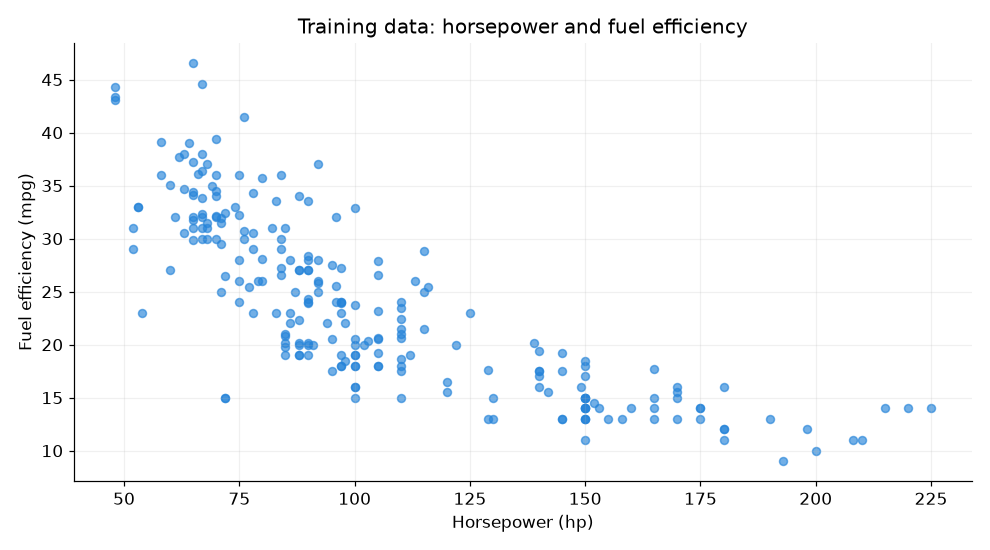

In [3]:
X = data[['horsepower']].to_numpy(dtype=float)
y = data['mpg'].to_numpy(dtype=float)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=SEED)
print(f'Training: {len(y_train)}, Validation: {len(y_val)}, Test: {len(y_test)}')

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X_train[:, 0], y_train, s=27, alpha=0.65, color=BLUE)
ax.set(xlabel='Horsepower (hp)', ylabel='Fuel efficiency (mpg)', title='Training data: horsepower and fuel efficiency')
ax.grid(alpha=0.18)
fig.tight_layout()
fig.savefig(OUT / '01_training_data.png', dpi=180)
plt.show()

## 3. SVRの予測曲線とεの帯

予測値を $f(x)$、観測値を $y$ とすると、ε不感損失は次の式です。

$$L_\varepsilon(y,f(x))=\max(0,|y-f(x)|-\varepsilon).$$

予測値の上下ε以内なら損失はゼロです。外側では、帯からはみ出した分だけ損失が増えます。帯の全幅は $2\varepsilon$ です。**この帯は信頼区間や予測区間ではありません。**

RBFカーネルは $K(x,u)=\exp(-\gamma\|x-u\|^2)$ です。近い入力ほど大きい値になります。

| 設定 | 役割 |
|---|---|
| `epsilon` | 誤差に対して損失を与えない片側の幅 |
| `C` | 帯の外の誤差へのペナルティをどれだけ重くするか |
| `gamma` | RBFカーネルがどのくらい狭い範囲に影響するか |

ここでは、**入力の馬力だけを標準化**します。出力のmpgは変換しないため、`epsilon=2` は「±2 mpg」を意味します。`gamma`は標準化後の入力空間での値です。標準化とSVRをPipelineにまとめ、検証や交差検証のデータが標準化の学習に混ざらないようにします。

Support vectors: 139 / 234
Training samples inside tube: 100
Mean epsilon-insensitive training loss: 1.648


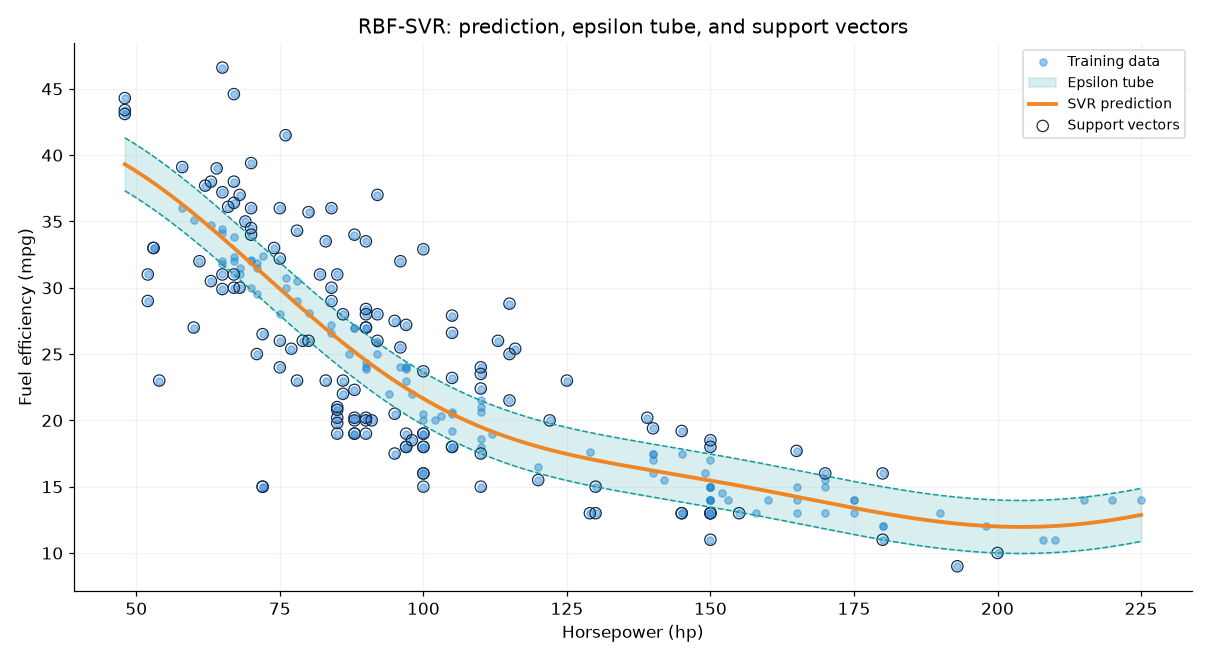

,MAE (mpg),RMSE (mpg),R2
Validation,3.144404,4.433631,0.593584


In [4]:
def make_svr(C=30.0, gamma=0.3, epsilon=2.0, kernel='rbf'):
    return Pipeline([
        ('scale', StandardScaler()),
        ('svr', SVR(kernel=kernel, C=C, gamma=gamma, epsilon=epsilon))
    ])

grid = np.linspace(X_train.min(), X_train.max(), 450).reshape(-1, 1)

def metrics(model, features, target):
    pred = model.predict(features)
    return {'MAE (mpg)': mean_absolute_error(target, pred),
            'RMSE (mpg)': np.sqrt(mean_squared_error(target, pred)),
            'R2': r2_score(target, pred)}

def plot_svr(ax, model, X_fit, y_fit, title, prediction_grid=None, show_support=True):
    if prediction_grid is None:
        prediction_grid = grid
    pred = model.predict(prediction_grid)
    svr = model.named_steps['svr']
    eps = svr.epsilon
    ax.scatter(X_fit[:, 0], y_fit, s=22, color=BLUE, alpha=0.45, label='Training data')
    ax.fill_between(prediction_grid[:, 0], pred-eps, pred+eps, color=TEAL, alpha=0.16, label='Epsilon tube')
    ax.plot(prediction_grid[:, 0], pred-eps, '--', color=TEAL, lw=1)
    ax.plot(prediction_grid[:, 0], pred+eps, '--', color=TEAL, lw=1)
    ax.plot(prediction_grid[:, 0], pred, color=ORANGE, lw=2.5, label='SVR prediction')
    if show_support:
        ids = svr.support_  # indices refer to this model's training rows
        ax.scatter(X_fit[ids, 0], y_fit[ids], facecolors='none', edgecolors=NAVY,
                   s=55, linewidths=0.8, label='Support vectors')
    ax.set(xlabel='Horsepower (hp)', ylabel='Fuel efficiency (mpg)', title=title)
    ax.grid(alpha=0.15)

demo = make_svr().fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(11, 6))
plot_svr(ax, demo, X_train, y_train, 'RBF-SVR: prediction, epsilon tube, and support vectors')
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUT / '02_svr_epsilon_tube.png', dpi=180)
plt.show()

residual = y_train - demo.predict(X_train)
eps = demo.named_steps['svr'].epsilon
loss = np.maximum(0, np.abs(residual)-eps)
print('Support vectors:', len(demo.named_steps['svr'].support_), '/', len(y_train))
print('Training samples inside tube:', int(np.sum(np.abs(residual) <= eps+1e-3)))
print('Mean epsilon-insensitive training loss:', round(float(loss.mean()), 3))
display(pd.DataFrame([metrics(demo, X_val, y_val)], index=['Validation']))

丸で囲んだ点がサポートベクターです。帯の境界付近や外側の点が、予測関数の決定に関わります。実データのばらつきが大きいと、サポートベクターは多くなります。「必ず少数になる」という意味ではありません。数値計算の許容誤差により、帯の境界と見た目が完全には一致しない場合もあります。

図の曲線は、使った入力範囲での推定です。同じ馬力でも燃費が違う車があるため、一本の曲線ですべての点を通ることはできません。

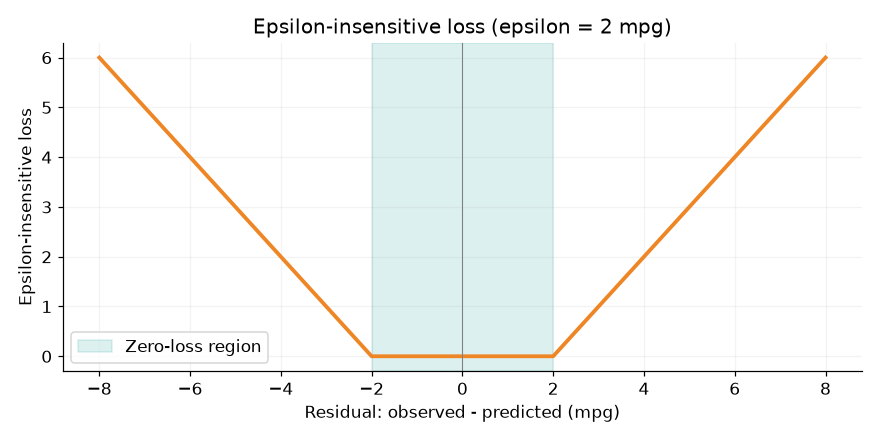

In [5]:
errors = np.linspace(-8, 8, 401)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(errors, np.maximum(0, np.abs(errors)-eps), color=ORANGE, lw=2.5)
ax.axvspan(-eps, eps, color=TEAL, alpha=0.15, label='Zero-loss region')
ax.axvline(0, color='gray', lw=0.7)
ax.set(xlabel='Residual: observed - predicted (mpg)', ylabel='Epsilon-insensitive loss',
       title=f'Epsilon-insensitive loss (epsilon = {eps:g} mpg)')
ax.legend(); ax.grid(alpha=0.15)
fig.tight_layout(); fig.savefig(OUT / '03_epsilon_loss.png', dpi=180)
plt.show()

## 4. 直線の回帰と比べる

最小二乗法による線形回帰、線形カーネルのSVR、RBFカーネルのSVRを、同じ訓練・検証データで比べます。

線形回帰と線形SVRはどちらも直線ですが、損失や正則化が異なります。RBF-SVRは曲線を表せます。ここでの設定はデモ用で、各手法を最適に調整した比較ではありません。

**MAE** は誤差の絶対値の平均、**RMSE** は二乗誤差の平均の平方根です。どちらも単位はmpgで、小さいほどよい値です。**R²** は1が最良で、負になる場合もあります。分類の正解率とは異なります。

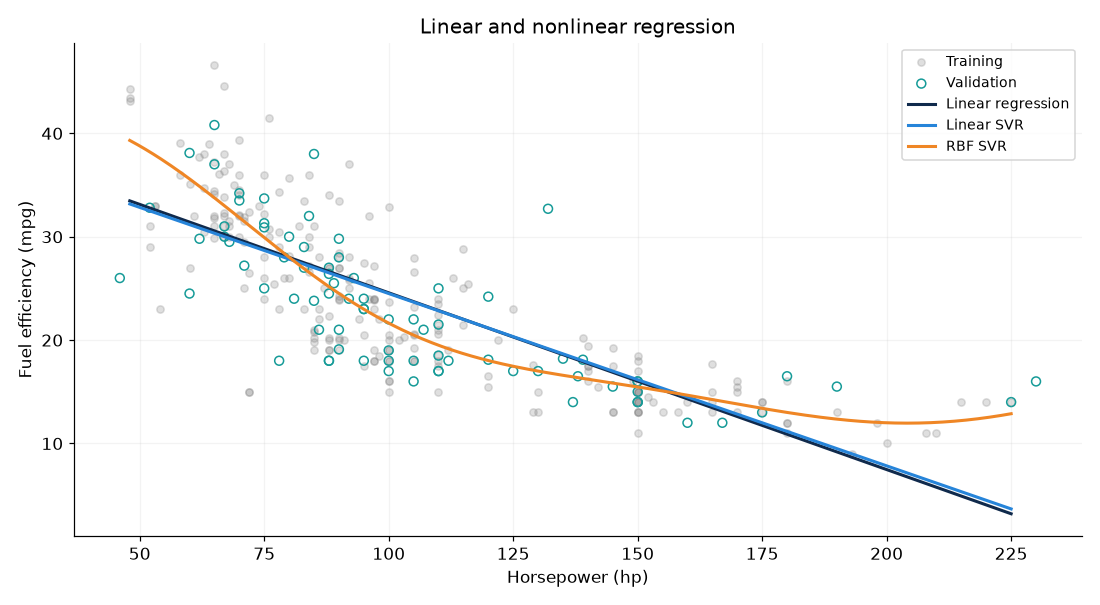

,MAE (mpg),RMSE (mpg),R2
Model,,,
Linear regression,3.871,5.052,0.472
Linear SVR,3.850,5.005,0.482
RBF SVR,3.144,4.434,0.594


In [6]:
models = {
    'Linear regression': LinearRegression(),
    'Linear SVR': make_svr(kernel='linear'),
    'RBF SVR': make_svr()
}
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(X_train[:, 0], y_train, color='gray', alpha=0.25, s=23, label='Training')
ax.scatter(X_val[:, 0], y_val, facecolors='none', edgecolors=TEAL, s=34, label='Validation')
rows=[]
for (name, model), color in zip(models.items(), [NAVY, BLUE, ORANGE]):
    model.fit(X_train, y_train)
    ax.plot(grid[:, 0], model.predict(grid), color=color, lw=2, label=name)
    rows.append({'Model': name, **metrics(model, X_val, y_val)})
ax.set(xlabel='Horsepower (hp)', ylabel='Fuel efficiency (mpg)', title='Linear and nonlinear regression')
ax.legend(fontsize=9); ax.grid(alpha=0.15)
fig.tight_layout(); fig.savefig(OUT / '04_model_comparison.png', dpi=180)
plt.show()
display(pd.DataFrame(rows).set_index('Model').round(3))

## 5. C・γ・εを一つずつ変更する

一度に一つの設定だけを変え、ほかの設定を固定して比べます。背景の点はすべて同じ訓練データです。各図のMAEは検証データで計算します。

- **C**：大きくすると、帯からはみ出す誤差を強く抑えようとします。
- **γ**：大きくすると影響する範囲が狭まり、局所的な曲がりを表しやすくなります。
- **ε**：大きくすると、損失を与えない帯が広がります。

大きくすれば性能がよくなるとは限りません。曲線の形、検証誤差、サポートベクター数を一緒に見てください。

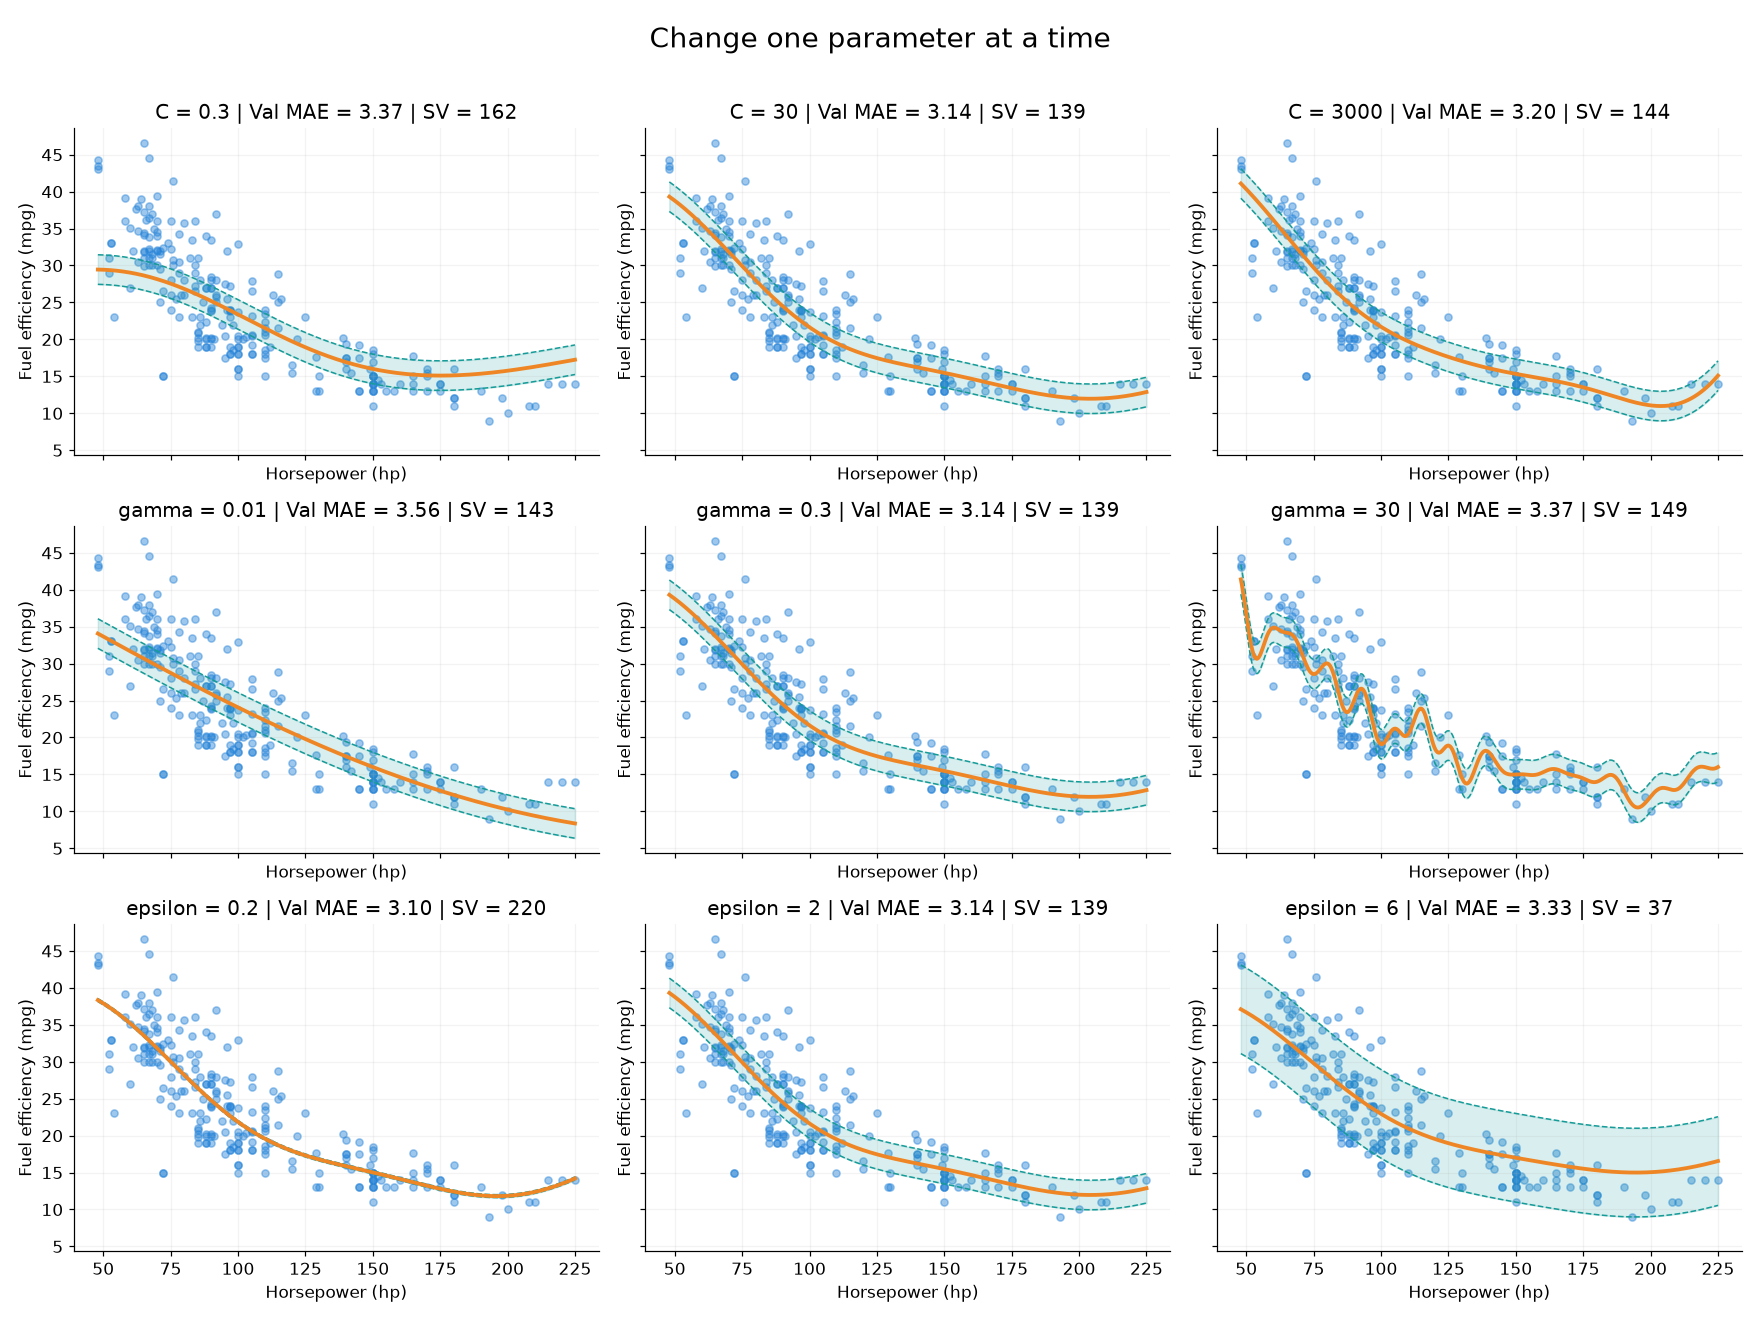

,Changed,Value,Validation MAE,Support vectors
0,C,0.30,3.367,162
1,C,30.00,3.144,139
2,C,3000.00,3.202,144
3,gamma,0.01,3.563,143
4,gamma,0.30,3.144,139
5,gamma,30.00,3.374,149
6,epsilon,0.20,3.096,220
7,epsilon,2.00,3.144,139
8,epsilon,6.00,3.333,37


In [7]:
experiments = [('C', [0.3, 30.0, 3000.0]),
               ('gamma', [0.01, 0.3, 30.0]),
               ('epsilon', [0.2, 2.0, 6.0])]
fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharex=True, sharey=True)
sensitivity_rows=[]
for row, (parameter, values) in enumerate(experiments):
    for col, value in enumerate(values):
        settings = dict(C=30.0, gamma=0.3, epsilon=2.0)
        settings[parameter] = value
        model = make_svr(**settings).fit(X_train, y_train)
        score = metrics(model, X_val, y_val)['MAE (mpg)']
        nsv = len(model.named_steps['svr'].support_)
        plot_svr(axes[row, col], model, X_train, y_train,
                 f'{parameter} = {value:g} | Val MAE = {score:.2f} | SV = {nsv}', show_support=False)
        sensitivity_rows.append({'Changed':parameter, 'Value':value,
                                 'Validation MAE':score, 'Support vectors':nsv})
fig.suptitle('Change one parameter at a time', fontsize=18)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(OUT / '05_parameter_comparison.png', dpi=180)
plt.show()
display(pd.DataFrame(sensitivity_rows).round(3))

## 6. 自分で設定を変える（Colabフォーム）

次のセルの値を変更して、セルを再実行してください。Colabではフォームとして入力できます。Cとgammaは10の何乗かを指定します。例えば `log10_gamma=-1` は `gamma=0.1` です。

このセルが使うのは訓練・検証データだけです。ここで試した設定は、次の交差検証の探索範囲に自動では反映されません。

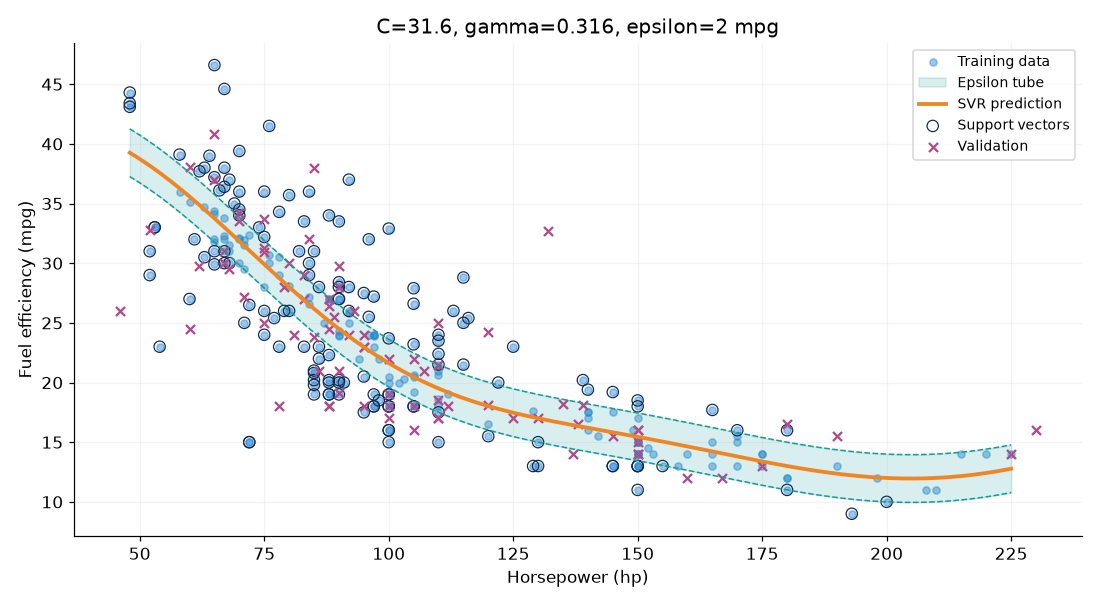

,MAE (mpg),RMSE (mpg),R2
Validation,3.145,4.43,0.594


In [8]:
# @title RBF-SVRの設定を変更
log10_C = 1.5 # @param {type:"slider", min:-1, max:4, step:0.5}
log10_gamma = -0.5 # @param {type:"slider", min:-3, max:2, step:0.5}
epsilon_mpg = 2.0 # @param {type:"slider", min:0, max:8, step:0.5}
settings = dict(C=10.0**log10_C, gamma=10.0**log10_gamma, epsilon=epsilon_mpg)
interactive_model = make_svr(**settings).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(10, 5.5))
plot_svr(ax, interactive_model, X_train, y_train,
         f'C={settings["C"]:.3g}, gamma={settings["gamma"]:.3g}, epsilon={epsilon_mpg:g} mpg')
ax.scatter(X_val[:, 0], y_val, marker='x', s=35, color='#ad4b8b', label='Validation')
ax.legend(fontsize=9); fig.tight_layout()
fig.savefig(OUT / '06_your_settings.png', dpi=180)
plt.show()
display(pd.DataFrame([metrics(interactive_model, X_val, y_val)], index=['Validation']).round(3))

## 7. 交差検証で設定を選ぶ

ここでは元の訓練部分と検証部分を合わせた **開発用データ（X_dev）** に対して、5分割交差検証を行います。前の実習で検証部分を観察したため、交差検証値は設定選択の参考値として扱い、最終的な汎化性能はまだ使っていないテストデータで確認します。

線形SVRとRBF-SVRについて、あらかじめ指定した範囲で平均絶対誤差が小さい設定を選びます。各分割ではStandardScalerも訓練側だけで学習されます。`refit=True` により、選ばれた設定で開発用データ全体を使って自動的に学習し直します。

探索範囲は有限なので、ここで得られるのは「試した候補の中での最良設定」です。テスト結果を見て探索範囲を変更すると、テストがモデル選択に混ざるので注意してください。

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
search_spaces = {
    'Linear SVR': {'svr__kernel':['linear'], 'svr__C':[1.0, 30.0, 300.0],
                   'svr__epsilon':[0.5, 2.0, 4.0]},
    'RBF SVR': {'svr__kernel':['rbf'], 'svr__C':[1.0, 30.0, 300.0],
                'svr__gamma':[0.03, 0.3, 3.0], 'svr__epsilon':[0.5, 2.0, 4.0]}
}
searches = {}
for name, space in search_spaces.items():
    search = GridSearchCV(make_svr(), space, scoring='neg_mean_absolute_error',
                          cv=cv, n_jobs=1, refit=True, error_score='raise')
    search.fit(X_dev, y_dev)
    searches[name] = search
    print(name, '| CV MAE:', round(-search.best_score_, 3))
    print('Best settings:', search.best_params_)

rbf_results = pd.DataFrame(searches['RBF SVR'].cv_results_)
rbf_results['CV MAE (mpg)'] = -rbf_results['mean_test_score']
display(rbf_results.sort_values('rank_test_score')[
    ['param_svr__C','param_svr__gamma','param_svr__epsilon',
     'CV MAE (mpg)','std_test_score','rank_test_score']].head(8).round(3))

Linear SVR | CV MAE: 3.85
Best settings: {'svr__C': 300.0, 'svr__epsilon': 0.5, 'svr__kernel': 'linear'}
RBF SVR | CV MAE: 3.24
Best settings: {'svr__C': 300.0, 'svr__epsilon': 0.5, 'svr__gamma': 0.3, 'svr__kernel': 'rbf'}


,param_svr__C,param_svr__gamma,param_svr__epsilon,CV MAE (mpg),std_test_score,rank_test_score
19,300.0,0.30,0.5,3.240,0.489,1
10,30.0,0.30,0.5,3.242,0.495,2
13,30.0,0.30,2.0,3.261,0.479,3
14,30.0,3.00,2.0,3.264,0.425,4
21,300.0,0.03,2.0,3.266,0.461,5
11,30.0,3.00,0.5,3.267,0.443,6
18,300.0,0.03,0.5,3.267,0.464,7
24,300.0,0.03,4.0,3.272,0.460,8


## 8. 設定を固定して、最後にテストする

ここで初めて、取り分けておいたテストデータを使います。比較対象と設定は前の段階で決めています。この結果を見た後に調整したモデルには、別の最終評価用データが必要です。

RBF-SVRの図では、開発用データで学習した曲線と帯、そしてテストの観測値を表示します。εの帯に入った割合も計算しますが、これは単に「誤差が±ε以内だった割合」であり、信頼水準や、将来の被覆率の保証ではありません。

Final epsilon: 0.5 mpg
Test observations within +/- epsilon: 7.6% (not a confidence level)
Support vectors: 274 / 313


,MAE (mpg),RMSE (mpg),R2
Linear regression,3.783,4.707,0.566
Linear SVR,3.774,4.753,0.557
RBF SVR,3.268,4.207,0.653


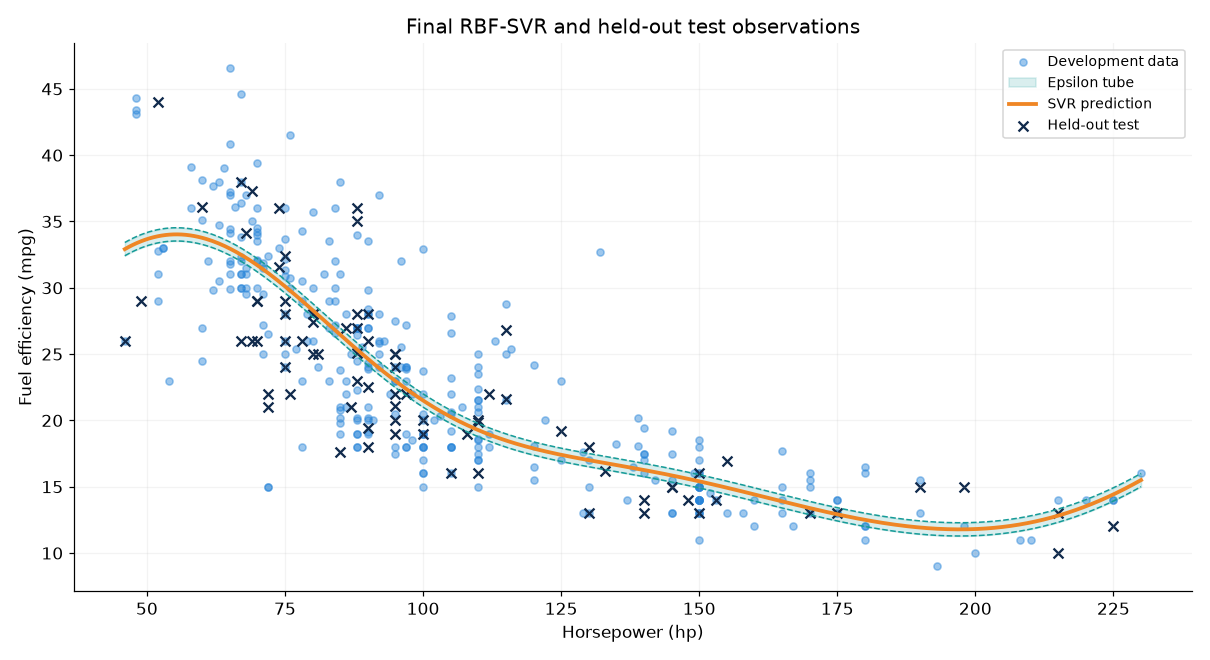

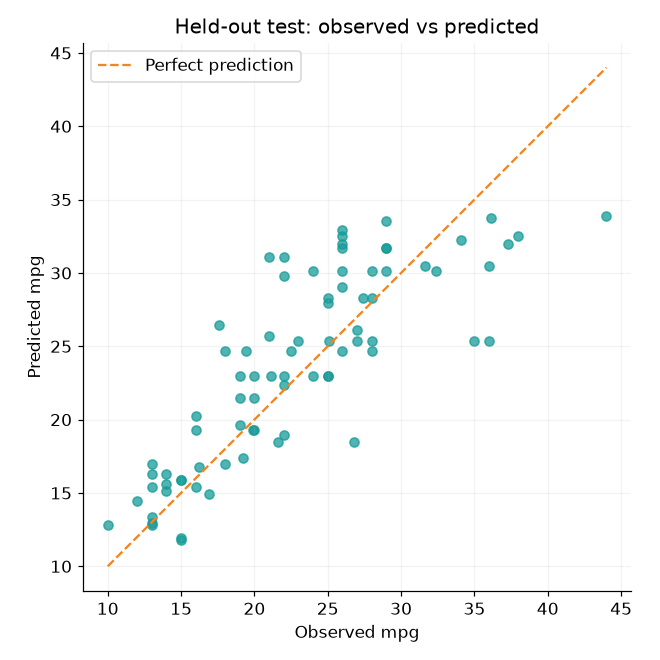

In [10]:
final_models = {'Linear regression': LinearRegression().fit(X_dev, y_dev),
                **{name: search.best_estimator_ for name, search in searches.items()}}
test_table = pd.DataFrame({name: metrics(model, X_test, y_test)
                          for name, model in final_models.items()}).T
display(test_table.round(3))
test_table.to_csv(OUT / 'test_metrics.csv', index_label='Model')

best = final_models['RBF SVR']
grid_final = np.linspace(X_dev.min(), X_dev.max(), 500).reshape(-1,1)
fig, ax = plt.subplots(figsize=(11, 6))
plot_svr(ax, best, X_dev, y_dev, 'Final RBF-SVR and held-out test observations',
         prediction_grid=grid_final, show_support=False)
# Here the fit data are the full development set.
handles, labels = ax.get_legend_handles_labels()
labels = ['Development data' if x=='Training data' else x for x in labels]
test_artist = ax.scatter(X_test[:,0], y_test, marker='x', color=NAVY, s=42, label='Held-out test')
ax.legend(handles+[test_artist], labels+['Held-out test'], fontsize=9)
fig.tight_layout(); fig.savefig(OUT / '07_final_test.png', dpi=180)
plt.show()

pred = best.predict(X_test)
final_eps = best.named_steps['svr'].epsilon
inside_rate = np.mean(np.abs(y_test-pred) <= final_eps)
print(f'Final epsilon: {final_eps:g} mpg')
print(f'Test observations within +/- epsilon: {inside_rate:.1%} (not a confidence level)')
print('Support vectors:', len(best.named_steps['svr'].support_), '/', len(y_dev))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, pred, color=TEAL, alpha=0.75)
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
ax.plot([lo,hi],[lo,hi],'--',color=ORANGE,label='Perfect prediction')
ax.set(xlabel='Observed mpg', ylabel='Predicted mpg', title='Held-out test: observed vs predicted')
ax.set_aspect('equal',adjustable='box'); ax.grid(alpha=0.15); ax.legend()
fig.tight_layout(); fig.savefig(OUT / '08_observed_predicted.png', dpi=180)
plt.show()

## 9. 考えてみよう

1. 線形SVRとRBF-SVRでは、馬力の低い領域・高い領域の曲線がどう違いますか。
2. εを大きくしたとき、帯の幅、サポートベクター数、検証誤差はどう変化しましたか。すべてが単調に変わるといえるでしょうか。
3. γを大きくしすぎた曲線は、データが少ない場所でどう振る舞いますか。
4. この実習では燃費を馬力だけで説明しています。重量や年式を追加すると、何が改善しそうですか。その場合、二次元の曲線図をどう解釈すればよいでしょうか。
5. このデータの範囲を大きく外れた馬力に予測を使ってよいでしょうか。RBFカーネルの距離に対する性質から考えてください。

**押さえたい点**：SVRは、小さな誤差をεの帯で許しながら、誤差へのペナルティと関数の複雑さを調整します。RBFカーネルを使うと、元の入力に対して曲がった予測関数を表せます。曲線の見た目だけでなく、学習に使わないデータで性能を確認しましょう。

## 図を保存する

次のセルは、作成した図と評価表をZIPにまとめます。Colab左側のファイル一覧で `svr_outputs.zip` を右クリックしてダウンロードできます。

## 参考資料

- [UCI Auto MPG：データ・出典・ライセンス](https://archive.ics.uci.edu/dataset/9/auto%2Bmpg)
- [scikit-learn SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html)
- [scikit-learn：SVMの回帰](https://scikit-learn.org/stable/modules/svm.html#regression)
- [scikit-learn：データ漏洩とPipeline](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

In [11]:
import shutil
archive_path = shutil.make_archive('svr_outputs', 'zip', OUT)
print('Saved:', archive_path)
print('PNG files:', len(list(OUT.glob('*.png'))))
# Colabから直接ダウンロードする場合は、次の2行のコメントを外してください。
# from google.colab import files
# files.download(archive_path)

Saved: svr_outputs.zip
PNG files: 8
